# Taller de Machine Learning supervisado - Vocales

**Asignatura:** Inteligencia Artificial - Universidad del Magdalena

**Curso:** IA-2026-II  |  **Tema:** Machine Learning - Reconocimiento óptico de caracteres (OCR)

**Integrantes:** Carlos Pinto, León Cantillo, Santiago Gonzales, Jorge García.

## Contenido del equipo
- Clases asignadas: vocales **A, E, I, O, U**.
- La vocal **O** se representa con la carpeta **`0`** (no existe un directorio propio para la letra O, por similitud visual con el dígito cero).

## Alcance de este archivo
Este notebook analiza **únicamente las vocales**. Se excluyen los números del 1 al 9 y las letras que no son vocales. Incluye la descripción del problema, la inspección del conjunto de datos, el preprocesamiento (conversión a blanco y negro), el diseño de experimentos y la implementación de **árboles de decisión** con `GridSearchCV`, junto con el análisis de resultados y las conclusiones.


## 1. Descripción del problema y objetivo

El reconocimiento óptico de caracteres (OCR) convierte imágenes de texto manuscrito o impreso en texto digital editable. En este trabajo se aborda una versión reducida del problema: clasificar una imagen de un carácter manuscrito en una de las cinco vocales del español (**A, E, I, O, U**). Es un problema de **clasificación supervisada multiclase**, porque cada imagen tiene asociada una etiqueta conocida durante el entrenamiento.

El conjunto de datos asignado contiene también dígitos y consonantes. Para este trabajo se conservan solo las carpetas de las vocales y se usa la carpeta `0` como aproximación de la vocal **O**. Esa decisión debe considerarse al interpretar los resultados, porque la letra O y el dígito 0 son símbolos distintos aunque compartan una forma cerrada.

| Elemento | Descripción |
|---|---|
| Casos | 5.070 imágenes de vocales |
| Variables de entrada | 7.500 píxeles por imagen (75 de ancho x 100 de alto), inicialmente en escala de grises |
| Variable objetivo | Vocal: `A`, `E`, `I`, `O`, `U` |
| Número de clases | 5 |
| Valores faltantes | 0 en las etiquetas; todas las imágenes son legibles |
| Origen | Kaggle: *Handwriting Letter and Number Dataset* |

**Objetivo:** construir y evaluar un clasificador basado en **árboles de decisión** que reconozca las cinco vocales a partir de imágenes binarizadas, ajustando sus hiperparámetros con `GridSearchCV` y reportando métricas de desempeño que permitan decidir si el modelo es adecuado.

La documentación del repositorio y la guía del trabajo se usaron para definir el problema, las variables y las etapas de experimentación.


## 2. Configuración y carga del dataset

Se configura la ruta del dataset y se cargan solo las carpetas de clase correspondientes a vocales. El dataset completo (**CNN letter Dataset**) no se incluye en este repositorio por su peso. Las imágenes binarizadas se guardan en `dataset/blanco y negro/`, una carpeta derivada que tampoco se versiona.


In [1]:
import os
import re
import time
import zipfile
import hashlib
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)

random.seed(42)
np.random.seed(42)
plt.rcParams["figure.dpi"] = 100

# ---------------------------------------------------------------
# CONFIGURACIÓN
# ---------------------------------------------------------------
# El dataset no se sube al repositorio: dataset/ está en .gitignore.
RUTA_DATASET = Path("dataset/normal/CNN letter Dataset")
RUTA_BN = Path("dataset/blanco y negro")
RUTA_ZIP = "archive (1).zip"
EXT = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tif", ".tiff"}

# Vocales que analiza este grupo. Se excluyen números 1-9 y otras letras.
VOCALES = ["A", "E", "I", "O", "U"]

def _tiene_clases(carpeta: Path) -> bool:
    subs = [d for d in carpeta.iterdir() if d.is_dir() and not d.name.startswith(("__", "."))]
    con_imgs = [d for d in subs if any(f.suffix.lower() in EXT for f in d.iterdir() if f.is_file())]
    return len(con_imgs) >= 2

def encontrar_raiz() -> Path:
    # Rutas explícitas: evita confundir el dataset original con la salida binarizada.
    for candidato in [RUTA_DATASET, Path("CNN letter Dataset")]:
        if candidato.is_dir() and _tiene_clases(candidato):
            return candidato
    for z in [Path(RUTA_ZIP), Path("/mnt/user-data/uploads") / RUTA_ZIP]:
        if z.is_file():
            destino = Path("dataset_extraido")
            if not destino.exists():
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(destino)
            break
    for base in [Path("dataset_extraido")]:
        if base.is_dir():
            for d in [base] + [x for x in base.rglob("*") if x.is_dir()]:
                if "__MACOSX" in d.parts or RUTA_BN == d or RUTA_BN in d.parents:
                    continue
                if _tiene_clases(d):
                    return d
    raise FileNotFoundError(
        "No se encontró el dataset. Ajuste RUTA_DATASET o RUTA_ZIP en esta celda."
    )

RAIZ = encontrar_raiz()
print("Dataset encontrado en:", RAIZ)
print("Salida blanco y negro:", RUTA_BN)


Dataset encontrado en: dataset/normal/CNN letter Dataset
Salida blanco y negro: dataset/blanco y negro


## 3. Organización de archivos y carpetas

Se muestra el árbol de carpetas restringido a las clases de vocales. Cada subcarpeta es una clase.


In [2]:
for carpeta, subs, archivos in os.walk(RAIZ):
    if "__MACOSX" in carpeta:
        continue
    nombre = Path(carpeta).name
    # Solo mostrar carpetas de clase vocales o la raíz
    if carpeta == str(RAIZ) or nombre in VOCALES or nombre == "0":
        nivel = len(Path(carpeta).relative_to(RAIZ).parts)
        print("  " * nivel + f"{nombre}/  ({len(archivos)} archivos)")

print("\nEjemplos de nombres de archivo por vocal:")
for d in sorted(x for x in RAIZ.iterdir() if x.is_dir() and (x.name in VOCALES or x.name == "0")):
    print(f"  {d.name}: {[f.name for f in sorted(d.iterdir())[:3]]}")


CNN letter Dataset/  (0 archivos)
  0/  (1030 archivos)
  A/  (1010 archivos)
  E/  (1010 archivos)
  I/  (1010 archivos)
  U/  (1010 archivos)

Ejemplos de nombres de archivo por vocal:
  0: ['aug17401_0.jpg', 'aug17402_1.jpg', 'aug17403_2.jpg']
  A: ['aug100_19.jpg', 'aug100_9.jpg', 'aug101_0.jpg']
  E: ['aug1061_0.jpg', 'aug1062_1.jpg', 'aug1063_2.jpg']
  I: ['aug2581_0.jpg', 'aug2582_1.jpg', 'aug2583_2.jpg']
  U: ['aug13601_0.jpg', 'aug13602_1.jpg', 'aug13603_2.jpg']


## 4. Cantidad de imágenes por clase

Se construye una tabla con la ruta, clase y formato de cada imagen. La carpeta `0` se mapea a la vocal `O`. Se excluyen del análisis las carpetas de números del 1 al 9 y demás letras que no sean vocales.


Total de imágenes (vocales): 5070
Clases (vocales): ['A', 'E', 'I', 'O', 'U']

Conteo por vocal:
clase
A    1010
E    1010
I    1010
O    1030
U    1010

Total: 5070
Razón entre la clase más y menos frecuente: 1.02


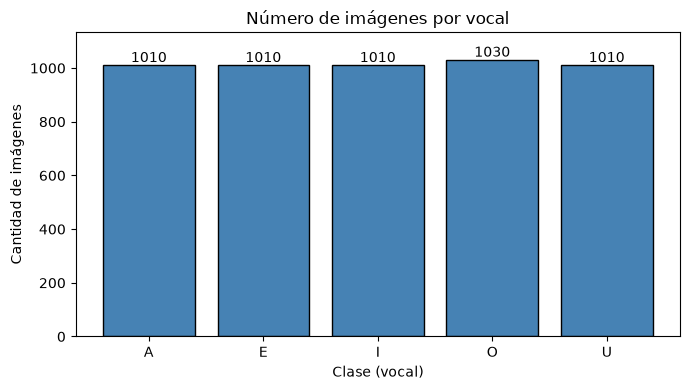

,ruta,clase,formato
0,dataset/normal/CNN letter Dataset/0/aug17401_0...,O,.jpg
1,dataset/normal/CNN letter Dataset/0/aug17402_1...,O,.jpg
2,dataset/normal/CNN letter Dataset/0/aug17403_2...,O,.jpg
3,dataset/normal/CNN letter Dataset/0/aug17404_3...,O,.jpg
4,dataset/normal/CNN letter Dataset/0/aug17405_4...,O,.jpg


In [3]:
registros = []
for p in RAIZ.rglob("*"):
    if p.is_file() and p.suffix.lower() in EXT and "__MACOSX" not in p.parts:
        clase = p.parent.name
        # Mapear carpeta '0' a vocal 'O'
        if clase == "0":
            clase = "O"
        # Filtrar solo vocales (excluir números 1-9 y otras letras)
        if clase in VOCALES:
            registros.append({"ruta": p, "clase": clase, "formato": p.suffix.lower()})

df = pd.DataFrame(registros)
CLASES = sorted(df["clase"].unique())

print("Total de imágenes (vocales):", len(df))
print("Clases (vocales):", CLASES)

conteo = df["clase"].value_counts().reindex(VOCALES).fillna(0).astype(int)
print("\nConteo por vocal:")
print(conteo.to_string())
print("\nTotal:", int(conteo.sum()))
print("Razón entre la clase más y menos frecuente:", round(conteo.max() / conteo.min(), 3))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(conteo.index, conteo.values, color="steelblue", edgecolor="black")
ax.set_title("Número de imágenes por vocal")
ax.set_xlabel("Clase (vocal)")
ax.set_ylabel("Cantidad de imágenes")
ax.set_ylim(0, conteo.max() * 1.1)
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()
df.head()


## 5. Muestras aleatorias por clase

Se seleccionan imágenes aleatorias de cada vocal y se muestran en una cuadrícula para observar variaciones de escritura, fondo, iluminación, grosor de trazo, rotación o ruido.


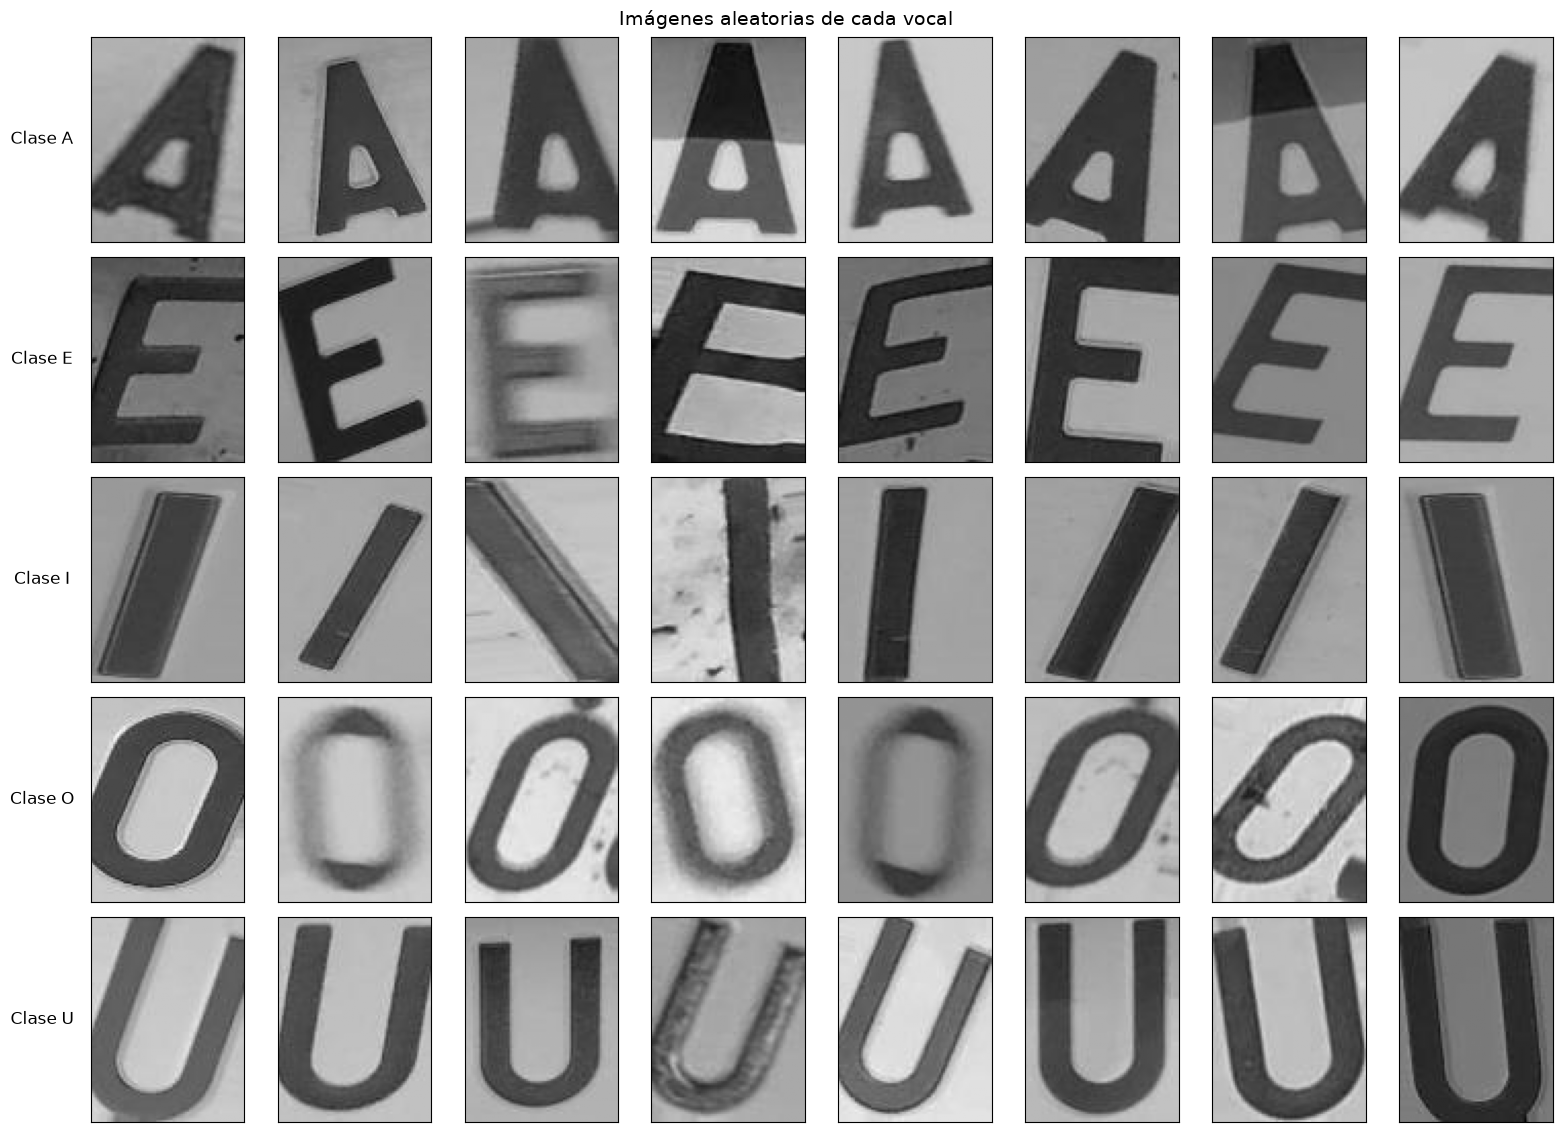

In [4]:
N_POR_CLASE = 8
rng = np.random.RandomState(7)

fig, axes = plt.subplots(len(CLASES), N_POR_CLASE, figsize=(2 * N_POR_CLASE, 2.3 * len(CLASES)))
for i, c in enumerate(CLASES):
    sub = df[df["clase"] == c]
    idx = rng.choice(len(sub), size=min(N_POR_CLASE, len(sub)), replace=False)
    for j, k in enumerate(idx):
        with Image.open(sub.iloc[k]["ruta"]) as im:
            a = np.array(im)
        ax = axes[i, j]
        ax.imshow(a, cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(f"Clase {c}", fontsize=12, rotation=0, labelpad=35, va="center")
fig.suptitle("Imágenes aleatorias de cada vocal", fontsize=14)
plt.tight_layout()
plt.show()


## 6. Dimensiones, canales y formato

Se verifican todas las imágenes del subconjunto de vocales: tamaño, modo de color, número de canales, tipo de dato y rango de intensidades. Se determina si todas tienen el mismo tamaño.


In [5]:
filas = []
for ruta, clase in zip(df["ruta"], df["clase"]):
    try:
        with Image.open(ruta) as im:
            a = np.array(im)
            filas.append({
                "clase": clase,
                "ancho": im.size[0],
                "alto": im.size[1],
                "modo": im.mode,
                "canales": 1 if a.ndim == 2 else a.shape[2],
                "dtype": str(a.dtype),
                "min": int(a.min()),
                "max": int(a.max()),
                "media": float(a.mean()),
                "desv": float(a.std()),
            })
    except Exception as e:
        filas.append({"clase": clase, "ancho": np.nan, "alto": np.nan, "modo": "ERROR",
                      "canales": np.nan, "dtype": "", "min": np.nan, "max": np.nan,
                      "media": np.nan, "desv": np.nan})

info = pd.DataFrame(filas)
info["ruta"] = df["ruta"].values

print("Tamaños (ancho, alto) y frecuencia:")
print(info.groupby(["ancho", "alto"]).size().to_string())
print("\nModos de color:\n", info["modo"].value_counts().to_string())
print("\nNúmero de canales:\n", info["canales"].value_counts().to_string())
print("\nTipo de dato:\n", info["dtype"].value_counts().to_string())
print("\nFormato de archivo:\n", df["formato"].value_counts().to_string())

mismo_tamano = info[["ancho", "alto"]].drop_duplicates().shape[0] == 1
print("\n¿Todas las imágenes tienen el mismo tamaño?", mismo_tamano)


Tamaños (ancho, alto) y frecuencia:
ancho  alto
75     100     5070

Modos de color:
 modo
L    5070

Número de canales:
 canales
1    5070

Tipo de dato:
 dtype
uint8    5070

Formato de archivo:
 formato
.jpg    5070

¿Todas las imágenes tienen el mismo tamaño? True


## 7. Calidad de los datos

Se revisa: imágenes corruptas o ilegibles, duplicados exactos por contenido, imágenes idénticas en clases distintas, brillo/contraste atípicos y el patrón de los nombres de archivo.


Imágenes corruptas: 0
Archivos duplicados exactos: 0
Contenidos repetidos en clases distintas: 0

Valores faltantes en la tabla de metadatos:
ruta       0
clase      0
formato    0

Imágenes con desviación estándar < 10 (poco contraste): 0


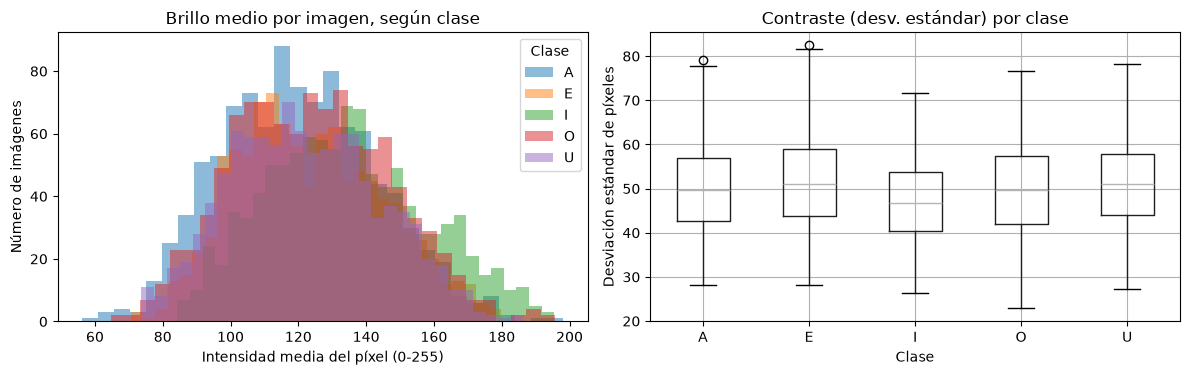


Archivos que siguen el patrón 'aug<id>_<sufijo>': 5070 de 5070


In [6]:
# 1) Imágenes corruptas o ilegibles
corruptas = []
for ruta in df["ruta"]:
    try:
        with Image.open(ruta) as im:
            im.verify()
    except Exception:
        corruptas.append(ruta)
print("Imágenes corruptas:", len(corruptas))

# 2) Duplicados exactos por contenido (hash MD5)
def md5(ruta):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        h.update(f.read())
    return h.hexdigest()

df["hash"] = [md5(r) for r in df["ruta"]]
print("Archivos duplicados exactos:", int(df["hash"].duplicated().sum()))
print("Contenidos repetidos en clases distintas:", int((df.groupby("hash")["clase"].nunique() > 1).sum()))

# 3) Valores faltantes en la tabla de metadatos
print("\nValores faltantes en la tabla de metadatos:")
print(df[["ruta", "clase", "formato"]].isna().sum().to_string())

# 4) Imágenes casi uniformes (poco contraste) o muy oscuras/claras
UMBRAL_DESV = 10
poco_contraste = info[info["desv"] < UMBRAL_DESV]
print(f"\nImágenes con desviación estándar < {UMBRAL_DESV} (poco contraste): {len(poco_contraste)}")
if len(poco_contraste):
    print(poco_contraste["clase"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for c in CLASES:
    axes[0].hist(info.loc[info["clase"] == c, "media"], bins=30, alpha=0.5, label=c)
axes[0].set_title("Brillo medio por imagen, según clase")
axes[0].set_xlabel("Intensidad media del píxel (0-255)")
axes[0].set_ylabel("Número de imágenes")
axes[0].legend(title="Clase")

info.boxplot(column="desv", by="clase", ax=axes[1])
axes[1].set_title("Contraste (desv. estándar) por clase")
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("Desviación estándar de píxeles")
plt.suptitle("")
plt.tight_layout()
plt.show()

# 5) Patrón de los nombres de archivo
patron = re.compile(r"^aug(\d+)_(\d+)$")
nombres = df["ruta"].apply(lambda p: Path(p).stem)
coincide = nombres.apply(lambda s: bool(patron.match(s)))
print(f"\nArchivos que siguen el patrón 'aug<id>_<sufijo>': {coincide.sum()} de {len(df)}")


## 8. Exploración gráfica adicional

### Imagen promedio por clase y distribución de intensidades

La imagen promedio permite ver qué forma "típica" tiene cada vocal; el histograma de intensidades ayuda a decidir si es necesario normalizar los píxeles.


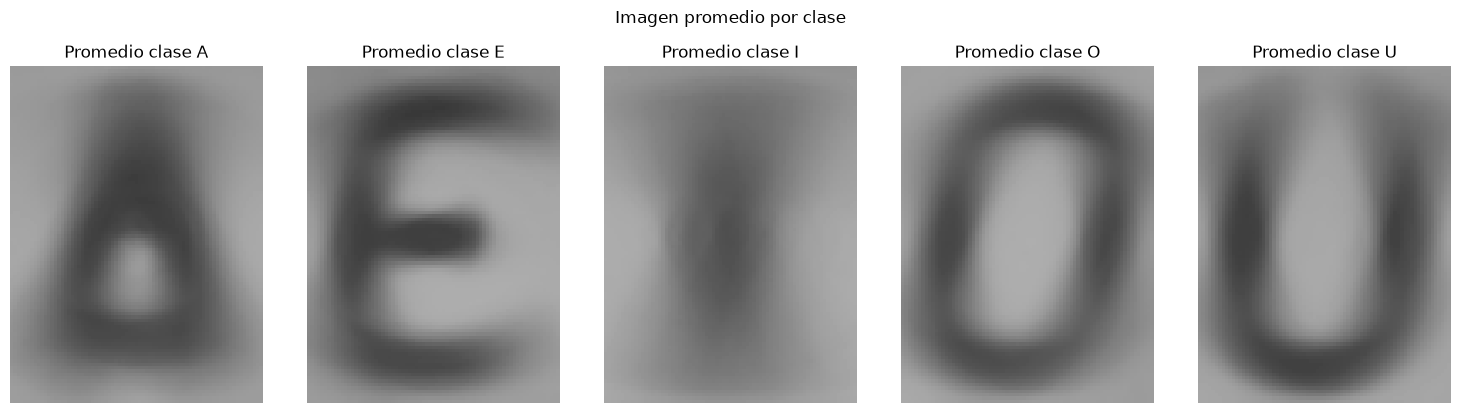

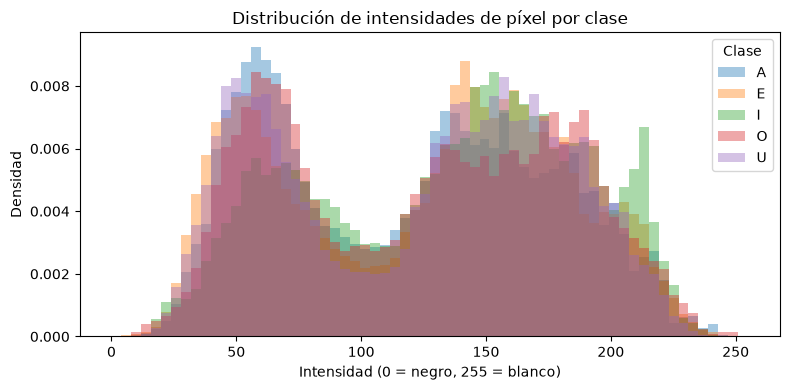

In [7]:
# Imagen promedio por clase
if not mismo_tamano:
    print("Las imágenes no tienen todas el mismo tamaño; se omite la imagen promedio.")
else:
    H, W = int(info["alto"].iloc[0]), int(info["ancho"].iloc[0])
    promedios = {}
    for c in CLASES:
        suma = np.zeros((H, W), dtype=np.float64)
        rutas = df.loc[df["clase"] == c, "ruta"]
        for r in rutas:
            with Image.open(r) as im:
                suma += np.array(im.convert("L"), dtype=np.float64)
        promedios[c] = suma / len(rutas)

    fig, axes = plt.subplots(1, len(CLASES), figsize=(3 * len(CLASES), 4))
    for ax, c in zip(axes, CLASES):
        ax.imshow(promedios[c], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"Promedio clase {c}")
        ax.axis("off")
    plt.suptitle("Imagen promedio por clase", y=1.02)
    plt.tight_layout()
    plt.show()

# Histograma de intensidades de píxel (muestra de 300 imágenes por clase)
fig, ax = plt.subplots(figsize=(8, 4))
for c in CLASES:
    sub = df[df["clase"] == c].sample(min(300, (df["clase"] == c).sum()), random_state=42)
    pix = np.concatenate([np.array(Image.open(r).convert("L")).ravel() for r in sub["ruta"]])
    ax.hist(pix, bins=64, range=(0, 255), alpha=0.4, density=True, label=c)
ax.set_title("Distribución de intensidades de píxel por clase")
ax.set_xlabel("Intensidad (0 = negro, 255 = blanco)")
ax.set_ylabel("Densidad")
ax.legend(title="Clase")
plt.tight_layout()
plt.show()


### 8.1 Matriz de correlación de estadísticas por imagen

Además del brillo y el contraste, se calcula la proporción de píxeles oscuros (tinta) con un umbral fijo de 128. La matriz de correlación permite detectar variables redundantes y entender si la intensidad aporta información independiente de la forma del trazo.


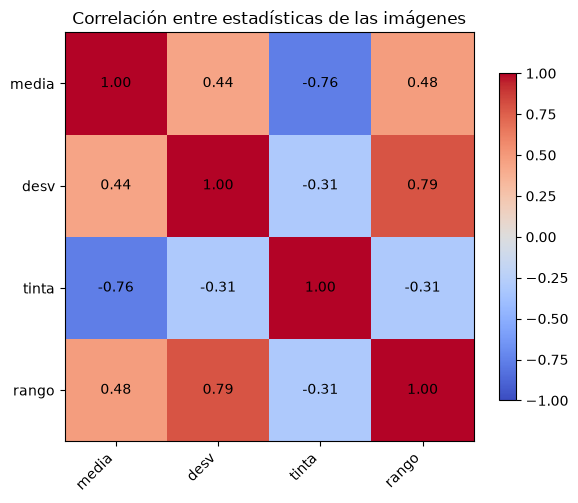

,media,desv,tinta,rango
media,1.000,0.440,-0.759,0.478
desv,0.440,1.000,-0.311,0.790
tinta,-0.759,-0.311,1.000,-0.305
rango,0.478,0.790,-0.305,1.000


In [8]:
# Estadísticas por imagen para la matriz de correlación
tinta_aprox = []
rango = []
for ruta in df["ruta"]:
    with Image.open(ruta) as im:
        gris = np.asarray(im.convert("L"))
    tinta_aprox.append(float((gris < 128).mean()))
    rango.append(int(gris.max()) - int(gris.min()))

estadisticas = info[["media", "desv"]].copy()
estadisticas["tinta"] = tinta_aprox
estadisticas["rango"] = rango
correlaciones = estadisticas.corr()

fig, ax = plt.subplots(figsize=(6, 5))
imagen = ax.imshow(correlaciones.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlaciones.columns)))
ax.set_yticks(range(len(correlaciones.columns)))
ax.set_xticklabels(correlaciones.columns, rotation=45, ha="right")
ax.set_yticklabels(correlaciones.columns)
for i in range(len(correlaciones)):
    for j in range(len(correlaciones)):
        ax.text(j, i, f"{correlaciones.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
ax.set_title("Correlación entre estadísticas de las imágenes")
fig.colorbar(imagen, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

correlaciones.round(3)


La proporción de tinta y el brillo medio presentan una correlación negativa fuerte: las imágenes más oscuras contienen más píxeles bajo el umbral. El contraste (`desv`) también se relaciona con la cantidad de tinta porque un trazo grueso separa mejor los dos niveles de intensidad. Estas relaciones confirman que el brillo global no debe usarse como característica directa: dos imágenes de la misma vocal pueden tener distinta iluminación. Por eso el preprocesamiento convierte cada imagen a blanco y negro antes de modelar.


## 9. Resumen cuantitativo de la inspección


In [9]:
resumen_final = pd.DataFrame({
    "Aspecto": [
        "Total de imágenes",
        "Número de clases",
        "Clases",
        "Imagen más/menos frecuente (razón)",
        "Formatos de archivo",
        "Tamaños distintos (ancho x alto)",
        "Modos de color",
        "Canales",
        "Imágenes corruptas",
        "Duplicados exactos",
        "Contenido repetido entre clases",
        "Imágenes con poco contraste",
    ],
    "Valor": [
        len(df),
        len(CLASES),
        ", ".join(CLASES),
        round(conteo.max() / conteo.min(), 3),
        ", ".join(df["formato"].unique()),
        "; ".join(f"{int(a)}x{int(b)}" for a, b in info[["ancho", "alto"]].drop_duplicates().values),
        ", ".join(info["modo"].unique()),
        ", ".join(str(int(x)) for x in info["canales"].dropna().unique()),
        len(corruptas),
        int(df["hash"].duplicated().sum()),
        int((df.groupby("hash")["clase"].nunique() > 1).sum()),
        len(poco_contraste),
    ],
})
resumen_final


,Aspecto,Valor
0,Total de imágenes,5070
1,Número de clases,5
2,Clases,"A, E, I, O, U"
3,Imagen más/menos frecuente (razón),1.02
4,Formatos de archivo,.jpg
5,Tamaños distintos (ancho x alto),75x100
6,Modos de color,L
7,Canales,1
8,Imágenes corruptas,0
9,Duplicados exactos,0


## 10. Tratamientos definidos a partir de la inspección

La inspección mostró que las 5.070 imágenes de vocales tienen el mismo tamaño (75x100), un solo canal, formato JPG, ninguna imagen corrupta, ningún duplicado exacto y clases prácticamente balanceadas (razón 1,02 entre la clase más y menos frecuente). Por tanto, no se eliminan registros ni se imputan valores.

Los tratamientos que sí se justifican son:

- **Conversión a blanco y negro:** el brillo y el contraste varían entre imágenes, así que se aplica un umbral de Otsu por imagen para separar tinta y fondo. Esto reduce el ruido de iluminación.
- **Mapeo de la clase `0` a `O`:** mantiene las cinco vocales y conserva la convención del dataset.
- **Vectorización:** cada imagen binarizada se aplana en 7.500 variables binarias (un píxel por variable), sin escalado, porque los árboles de decisión no lo requieren.
- **Partición agrupada:** los nombres `aug<id>_<sufijo>` indican variantes aumentadas del mismo trazo base. Para evitar fuga de información, la partición de entrenamiento y prueba se hace por grupo base, no por imagen individual.
- **Balanceo:** no es necesario; las clases están equilibradas.


## 11. Preprocesamiento: conversión a blanco y negro

### 11.1 Binarización con el método de Otsu

La inspección evidenció que la intensidad del fondo y del trazo cambia de una imagen a otra. Un umbral fijo produciría máscaras distintas según la iluminación, por lo que se usa el **método de Otsu**: para cada imagen se elige el umbral que maximiza la varianza entre dos grupos de píxeles (tinta y fondo). El resultado se guarda con tinta negra (`0`) y fondo blanco (`255`) en `dataset/blanco y negro/`.

Esta carpeta es un derivado del dataset y está excluida del control de versiones.


In [10]:
def umbral_otsu(imagen):
    """Calcula el umbral de Otsu de una imagen en escala de grises."""
    histograma = np.bincount(imagen.ravel(), minlength=256).astype(np.float64)
    probabilidad = histograma / histograma.sum()
    omega = np.cumsum(probabilidad)
    media_acumulada = np.cumsum(probabilidad * np.arange(256))
    media_total = media_acumulada[-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        varianza_entre = (media_total * omega - media_acumulada) ** 2 / (omega * (1 - omega))
    varianza_entre[~np.isfinite(varianza_entre)] = -1
    return int(np.argmax(varianza_entre))

def binarizar(ruta):
    """Devuelve la imagen binaria (tinta=0, fondo=255) y el umbral usado."""
    with Image.open(ruta) as im:
        gris = np.asarray(im.convert("L"))
    umbral = umbral_otsu(gris)
    return np.where(gris > umbral, 255, 0).astype(np.uint8), umbral

inicio = time.time()
RUTA_BN.mkdir(parents=True, exist_ok=True)
registros_bn = []
for ruta, clase in zip(df["ruta"], df["clase"]):
    binaria, umbral = binarizar(ruta)
    destino = RUTA_BN / clase / f"{ruta.stem}.png"
    destino.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(binaria, mode="L").save(destino)
    registros_bn.append({
        "ruta_original": ruta,
        "ruta_bn": destino,
        "clase": clase,
        "umbral": umbral,
        "tinta": float((binaria == 0).mean()),
    })

df_bn = pd.DataFrame(registros_bn)
print(f"Imágenes convertidas: {len(df_bn)} en {time.time() - inicio:.1f} s")
print(df_bn.groupby("clase")["umbral"].agg(["mean", "min", "max"]).round(1).to_string())


Imágenes convertidas: 5070 en 4.1 s
        mean  min  max
clase                 
A      114.6   59  166
E      113.8   68  175
I      119.4   69  174
O      116.2   60  192
U      111.3   70  164


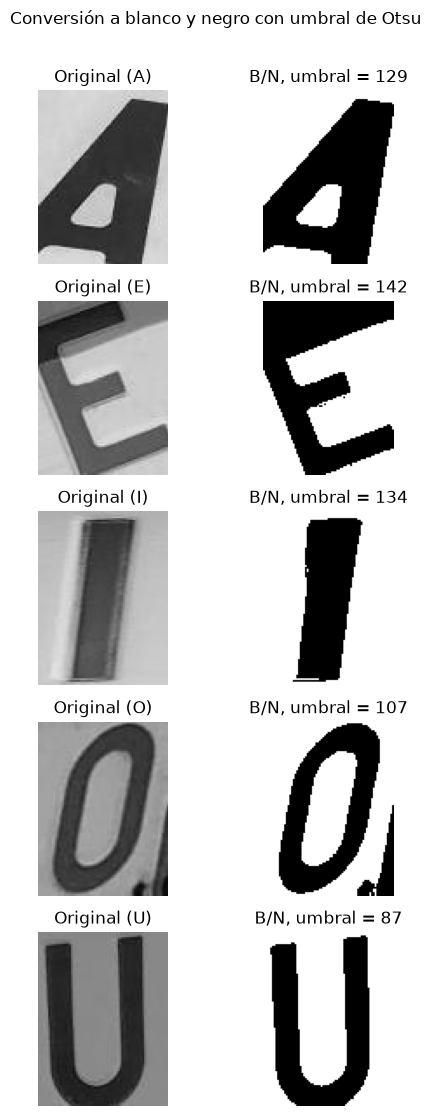

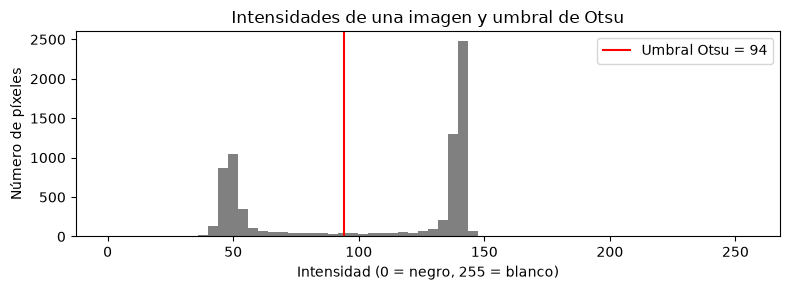

In [11]:
# Comparación visual: original en grises vs. imagen binarizada
muestras = df_bn.groupby("clase", group_keys=False).sample(1, random_state=42)
fig, axes = plt.subplots(len(muestras), 2, figsize=(5.5, 2.2 * len(muestras)))
for ax, (_, fila) in zip(axes, muestras.iterrows()):
    with Image.open(fila["ruta_original"]) as im:
        original = np.asarray(im.convert("L"))
    binaria = np.asarray(Image.open(fila["ruta_bn"]))
    ax[0].imshow(original, cmap="gray", vmin=0, vmax=255)
    ax[0].set_title(f"Original ({fila['clase']})")
    ax[0].axis("off")
    ax[1].imshow(binaria, cmap="gray", vmin=0, vmax=255)
    ax[1].set_title(f"B/N, umbral = {fila['umbral']}")
    ax[1].axis("off")
plt.suptitle("Conversión a blanco y negro con umbral de Otsu", y=1.01)
plt.tight_layout()
plt.show()

# Histograma de una imagen con su umbral
fila = df_bn.sample(1, random_state=7).iloc[0]
with Image.open(fila["ruta_original"]) as im:
    gris = np.asarray(im.convert("L"))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(gris.ravel(), bins=64, range=(0, 255), color="gray")
ax.axvline(fila["umbral"], color="red", label=f"Umbral Otsu = {fila['umbral']}")
ax.set_title("Intensidades de una imagen y umbral de Otsu")
ax.set_xlabel("Intensidad (0 = negro, 255 = blanco)")
ax.set_ylabel("Número de píxeles")
ax.legend()
plt.tight_layout()
plt.show()


### 11.2 Variables de entrada y partición de datos

Cada imagen binarizada se aplana en un vector de 7.500 posiciones (`1` = tinta, `0` = fondo). La variable objetivo es la vocal. El tamaño de la imagen es constante, por lo que no se requiere redimensionado.

Los nombres de archivo siguen el patrón `aug<id>_<sufijo>`, donde el identificador `<id>` agrupa variantes aumentadas del mismo trazo. Para que una variante del mismo trazo no quede en entrenamiento y otra en prueba, se usa una **partición agrupada y estratificada** (`StratifiedGroupKFold`): 80 % para entrenamiento y 20 % para prueba. El conjunto de prueba se reserva hasta la evaluación final.


In [12]:
# Matriz de características: 1 = tinta, 0 = fondo
X = np.stack([
    (np.asarray(Image.open(ruta)) == 0).astype(np.uint8).ravel()
    for ruta in df_bn["ruta_bn"]
])
y = df_bn["clase"].to_numpy()

# Grupo base a partir del nombre aug<id>_<sufijo>
base = df_bn["ruta_original"].apply(lambda r: re.match(r"aug(\d+)_", Path(r).stem).group(1))
grupos = (df_bn["clase"] + "_" + base).to_numpy()

particionador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_entrenamiento, idx_prueba = next(particionador.split(X, y, grupos))

X_ent, X_prueba = X[idx_entrenamiento], X[idx_prueba]
y_ent, y_prueba = y[idx_entrenamiento], y[idx_prueba]
g_ent, g_prueba = grupos[idx_entrenamiento], grupos[idx_prueba]

print("Forma de X:", X.shape, "| tipo:", X.dtype)
print("Entrenamiento:", X_ent.shape[0], "| Prueba:", X_prueba.shape[0])
print("Grupos compartidos entre entrenamiento y prueba:", len(set(g_ent) & set(g_prueba)))
print("\nDistribución de clases en prueba:")
print(pd.Series(y_prueba).value_counts().reindex(VOCALES).to_string())


Forma de X: (5070, 7500) | tipo: uint8
Entrenamiento: 4056 | Prueba: 1014
Grupos compartidos entre entrenamiento y prueba: 0

Distribución de clases en prueba:
A    202
E    202
I    202
O    206
U    202


La binarización conserva la forma del trazo y elimina diferencias globales de iluminación. El conjunto queda representado por 7.500 variables binarias, un número alto pero manejable para un árbol de decisión. La partición agrupada evita el optimismo artificial que aparecería si dos versiones aumentadas del mismo trazo se repartieran entre entrenamiento y prueba.


## 12. Árboles de decisión

Un árbol de decisión clasifica mediante una secuencia de reglas binarias sobre las variables de entrada. En cada nodo se elige el píxel y el umbral que más reducen la impureza de las clases; el crecimiento se detiene por profundidad, tamaño mínimo de hoja o pureza. La impureza se mide con **Gini** o **entropía**. El método no requiere escalado y es interpretable, pero puede sobreajustar si se deja crecer sin control.

### Referencia metodológica

Como referencia se revisó el repositorio de ejemplos de la profesora:

- [`tree/diabetes_indian_parte1_IA.ipynb`](https://github.com/idanis/IA_Unimagdalena/blob/main/tree/diabetes_indian_parte1_IA.ipynb): usa `DecisionTreeClassifier`, `criterion='entropy'`, `splitter='best'`, y evalúa con accuracy, matriz de confusión y `classification_report`.
- [`Random_Forest/regression_tree_example _ver2.ipynb`](https://github.com/idanis/IA_Unimagdalena/blob/main/Random_Forest/regression_tree_example%20_ver2.ipynb): ilustra `GridSearchCV` con `cv=5`, `best_params_` y evaluación final sobre el conjunto de prueba.

Este trabajo sigue esa estructura general y la adapta al dataset de imágenes: agrega binarización con Otsu, partición agrupada por aumento y métricas adicionales como balanced accuracy y F1 macro.

### 12.1 Diseño del experimento

Se ajustan los hiperparámetros con `GridSearchCV` sobre el conjunto de entrenamiento, usando validación cruzada agrupada y estratificada de 5 pliegues (`StratifiedGroupKFold`). El conjunto de prueba no participa en la búsqueda. La métrica de selección es *accuracy* y se registra también el desempeño en entrenamiento para detectar sobreajuste.

| Hiperparámetro | Valores evaluados | Efecto |
|---|---|---|
| `criterion` | `gini`, `entropy` | Medida de impureza de los nodos |
| `max_depth` | 6, 10, 14, sin límite | Controla la complejidad y el sobreajuste |
| `min_samples_leaf` | 1, 3 | Evita hojas con muy pocos casos |
| `max_features` | todas, `sqrt` | Número de píxeles considerados en cada división |


In [13]:
parametros_arbol = {
    "criterion": ["gini", "entropy"],
    "max_depth": [6, 10, 14, None],
    "min_samples_leaf": [1, 3],
    "max_features": [None, "sqrt"],
}

cv_arbol = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
busqueda_arbol = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=parametros_arbol,
    scoring="accuracy",
    cv=cv_arbol,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)

inicio = time.time()
busqueda_arbol.fit(X_ent, y_ent, groups=g_ent)
duracion_busqueda = time.time() - inicio

print(f"Combinaciones evaluadas: {len(busqueda_arbol.cv_results_['params'])}")
print(f"Tiempo de búsqueda: {duracion_busqueda:.1f} s")
print("Mejores hiperparámetros:")
for clave, valor in busqueda_arbol.best_params_.items():
    print(f"  {clave}: {valor}")
print(f"Mejor accuracy de validación cruzada: {busqueda_arbol.best_score_:.4f}")


Combinaciones evaluadas: 32
Tiempo de búsqueda: 61.0 s
Mejores hiperparámetros:
  criterion: entropy
  max_depth: 10
  max_features: None
  min_samples_leaf: 1
Mejor accuracy de validación cruzada: 0.9911


In [14]:
resultados_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
resultados_arbol["profundidad"] = resultados_arbol["param_max_depth"].apply(
    lambda valor: "sin límite" if pd.isna(valor) else str(valor)
)
resultados_arbol["variables"] = resultados_arbol["param_max_features"].apply(
    lambda valor: "todas" if pd.isna(valor) else str(valor)
)
columnas = ["rank_test_score", "param_criterion", "param_max_depth",
            "param_min_samples_leaf", "variables",
            "mean_train_score", "mean_test_score", "std_test_score"]
tabla_arbol = resultados_arbol.sort_values("rank_test_score")[columnas].head(10).copy()
for columna in ["mean_train_score", "mean_test_score", "std_test_score"]:
    tabla_arbol[columna] = tabla_arbol[columna].round(4)
tabla_arbol


,rank_test_score,param_criterion,param_max_depth,param_min_samples_leaf,variables,mean_train_score,mean_test_score,std_test_score
24,1,entropy,14,1,todas,1.0,0.9911,0.0033
28,1,entropy,None,1,todas,1.0,0.9911,0.0033
20,1,entropy,10,1,todas,1.0,0.9911,0.0033
6,4,gini,10,1,sqrt,1.0,0.9901,0.0042
14,4,gini,None,1,sqrt,1.0,0.9901,0.0042
10,4,gini,14,1,sqrt,1.0,0.9901,0.0042
22,7,entropy,10,1,sqrt,1.0,0.9901,0.0033
26,7,entropy,14,1,sqrt,1.0,0.9901,0.0033
30,7,entropy,None,1,sqrt,1.0,0.9901,0.0033
12,10,gini,None,1,todas,1.0,0.9894,0.0020


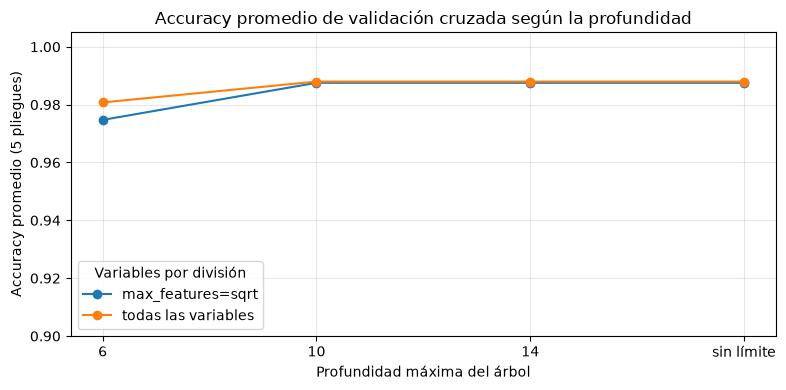

In [15]:
# Efecto de la profundidad y de max_features en la validación cruzada
resumen_cv = (resultados_arbol
              .groupby(["profundidad", "variables"])["mean_test_score"]
              .mean()
              .reset_index())
orden = ["6", "10", "14", "sin límite"]
fig, ax = plt.subplots(figsize=(8, 4))
for valor, grupo in resumen_cv.groupby("variables"):
    etiqueta = "todas las variables" if valor == "todas" else f"max_features={valor}"
    datos = grupo.set_index("profundidad").reindex(orden)
    ax.plot(orden, datos["mean_test_score"], marker="o", label=etiqueta)
ax.set_title("Accuracy promedio de validación cruzada según la profundidad")
ax.set_xlabel("Profundidad máxima del árbol")
ax.set_ylabel("Accuracy promedio (5 pliegues)")
ax.set_ylim(0.9, 1.005)
ax.grid(alpha=0.3)
ax.legend(title="Variables por división")
plt.tight_layout()
plt.show()


### 12.2 Evaluación sobre el conjunto de prueba

Se evalúa el mejor modelo una sola vez sobre las 1.014 imágenes reservadas. Se reportan *accuracy*, *balanced accuracy*, precisión, recall y F1 por clase, además de la matriz de confusión. Como el problema es de clasificación multiclase, las métricas de regresión (MSE, coeficiente de determinación y MAPE) no aplican; esas métricas corresponden a los métodos de regresión de la guía.


In [16]:
mejor_arbol = busqueda_arbol.best_estimator_
y_pred = mejor_arbol.predict(X_prueba)

accuracy_prueba = accuracy_score(y_prueba, y_pred)
accuracy_entrenamiento = accuracy_score(y_ent, mejor_arbol.predict(X_ent))
balanced = balanced_accuracy_score(y_prueba, y_pred)

print(f"Accuracy en entrenamiento: {accuracy_entrenamiento:.4f}")
print(f"Accuracy en prueba:        {accuracy_prueba:.4f}")
print(f"Balanced accuracy:         {balanced:.4f}")
print(f"Profundidad del árbol:     {mejor_arbol.get_depth()}")
print(f"Número de hojas:           {mejor_arbol.get_n_leaves()}")
print("\nReporte por clase:")
print(classification_report(y_prueba, y_pred, labels=CLASES, digits=4))


Accuracy en entrenamiento: 1.0000
Accuracy en prueba:        0.9901
Balanced accuracy:         0.9901
Profundidad del árbol:     9
Número de hojas:           41

Reporte por clase:
              precision    recall  f1-score   support

           A     1.0000    0.9901    0.9950       202
           E     1.0000    1.0000    1.0000       202
           I     0.9806    1.0000    0.9902       202
           O     0.9808    0.9903    0.9855       206
           U     0.9899    0.9703    0.9800       202

    accuracy                         0.9901      1014
   macro avg     0.9903    0.9901    0.9901      1014
weighted avg     0.9902    0.9901    0.9901      1014



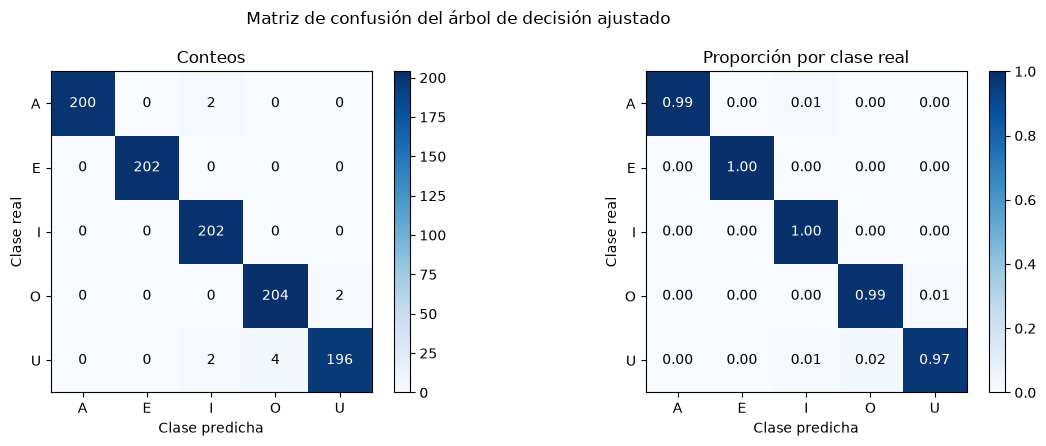

In [17]:
# Matriz de confusión: conteos y proporciones por clase real
matriz = confusion_matrix(y_prueba, y_pred, labels=CLASES)
matriz_norm = matriz / matriz.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, datos, titulo, formato in [
    (axes[0], matriz, "Conteos", "d"),
    (axes[1], matriz_norm, "Proporción por clase real", ".2f"),
]:
    imagen = ax.imshow(datos, cmap="Blues", vmin=0, vmax=datos.max())
    ax.set_xticks(range(len(CLASES)))
    ax.set_yticks(range(len(CLASES)))
    ax.set_xticklabels(CLASES)
    ax.set_yticklabels(CLASES)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(titulo)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            valor = datos[i, j]
            texto = f"{valor:{formato}}"
            ax.text(j, i, texto, ha="center", va="center",
                    color="white" if valor > datos.max() / 2 else "black")
    fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
plt.suptitle("Matriz de confusión del árbol de decisión ajustado")
plt.tight_layout()
plt.show()


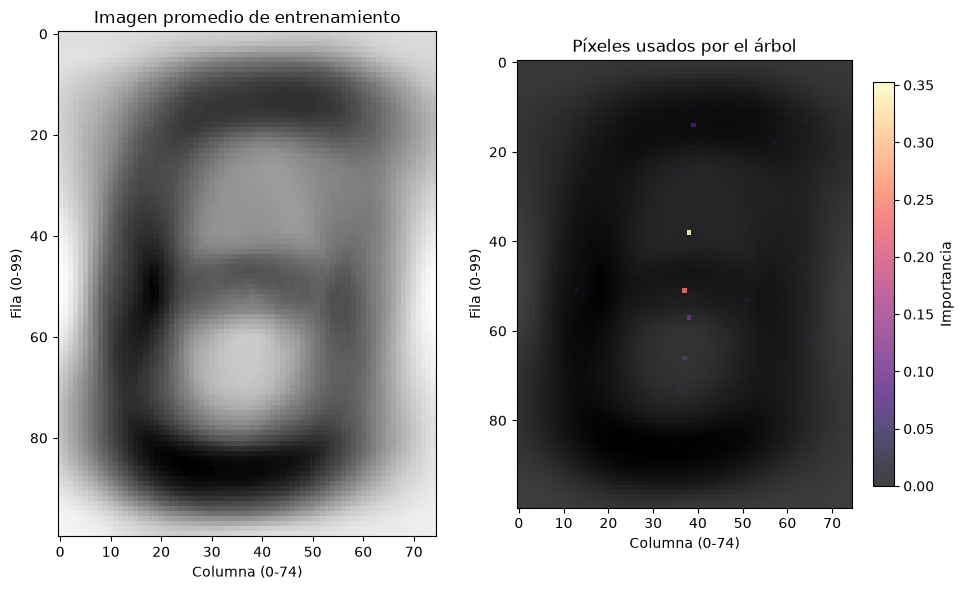

Píxeles más importantes (fila, columna, importancia):
  (38, 38): 0.3528
  (51, 37): 0.2416
  (14, 39): 0.0881
  (57, 38): 0.0809
  (66, 37): 0.0405
  (18, 57): 0.0225
  (53, 51): 0.0211
  (51, 13): 0.0199
  (73, 36): 0.0152
  (47, 27): 0.0138
Píxeles con importancia mayor que cero: 40 de 7500


In [18]:
# Importancia de los píxeles utilizados por el árbol
importancias = mejor_arbol.feature_importances_.reshape(100, 75)
promedio = X_ent.mean(axis=0).reshape(100, 75)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(promedio, cmap="gray_r")
axes[0].set_title("Imagen promedio de entrenamiento")
axes[0].set_xlabel("Columna (0-74)")
axes[0].set_ylabel("Fila (0-99)")
axes[1].imshow(promedio, cmap="gray_r")
imagen = axes[1].imshow(importancias, cmap="magma", alpha=0.75)
axes[1].set_title("Píxeles usados por el árbol")
axes[1].set_xlabel("Columna (0-74)")
axes[1].set_ylabel("Fila (0-99)")
fig.colorbar(imagen, ax=axes[1], shrink=0.8, label="Importancia")
plt.tight_layout()
plt.show()

print("Píxeles más importantes (fila, columna, importancia):")
for indice in np.argsort(importancias.ravel())[::-1][:10]:
    fila, columna = np.unravel_index(indice, importancias.shape)
    print(f"  ({fila}, {columna}): {importancias[fila, columna]:.4f}")
print(f"Píxeles con importancia mayor que cero: {np.count_nonzero(importancias)} de {importancias.size}")


### 12.3 Análisis del experimento

La búsqueda confirma que el problema es separable con reglas simples: el mejor árbol alcanza un accuracy de validación cruzada de 99,11 % y usa una fracción pequeña de los 7.500 píxeles. Las reglas se concentran en la zona central de la imagen, donde se diferencian la abertura de la A, los trazos horizontales de la E, la barra vertical de la I, el contorno cerrado de la O y la forma abierta de la U. Los píxeles del borde aportan poco porque el carácter está centrado y el fondo ya fue eliminado en la binarización.

Las profundidades 10, 14 y sin límite empatan en 99,11 % de accuracy de validación cruzada; `GridSearchCV` conserva la primera de las combinaciones empatadas y el modelo final queda con profundidad 10, la opción más simple entre ellas. La matriz de confusión muestra que los 10 errores se concentran en vocales de forma parecida: 2 casos de **A** predichos como **I**, 2 de **O** predichos como **U**, 2 de **U** predichos como **I** y 4 de **U** predichos como **O**. La clase con mayor recall es **E** (100 %) y la de menor recall es **U** (97,03 %), lo cual es coherente con su forma abierta y su parecido con la O.

La diferencia entre el accuracy de entrenamiento (100 %) y el de prueba (99,01 %) es de menos de un punto porcentual, lo que indica que la poda implícita de los hiperparámetros evita un sobreajuste severo. Sin embargo, un accuracy tan alto también sugiere que el conjunto es más sencillo que la escritura real: las imágenes son sintéticas, están centradas y comparten un estilo de trazo grueso.


## 13. Comparación entre los modelos

Esta rama del trabajo se enfoca en **árboles de decisión**. La comparación con los otros métodos de la guía (regresión multivariada, random forest, MLP y DNN) se integra en la versión final del equipo; aquí se comparan variantes del árbol para aislar el efecto de los hiperparámetros y de la representación de los datos.

Para decidir si el ajuste de hiperparámetros aporta una mejora real, se comparan cuatro alternativas sobre el mismo conjunto de prueba:

1. **Línea base:** predice siempre la clase más frecuente. Sirve para verificar que el modelo aprende algo más que el desbalance.
2. **Árbol sin ajuste:** hiperparámetros por defecto, sin límite de profundidad.
3. **Árbol ajustado:** mejores hiperparámetros encontrados por `GridSearchCV`, con los 7.500 píxeles.
4. **Árbol ajustado con reducción:** los mismos hiperparámetros sobre una versión reducida a 20x25 píxeles (500 variables), para medir el costo de conservar la resolución completa.

Todas las variantes usan la misma partición agrupada y se evalúan con accuracy, balanced accuracy y F1 macro.


In [19]:
def reducir_binarizada(matriz, ancho=20, alto=25):
    """Reduce cada imagen binaria a una cuadrícula de ancho x alto."""
    return np.stack([
        (np.asarray(Image.fromarray(fila.reshape(100, 75) * 255)
                    .resize((ancho, alto), Image.Resampling.BOX)) > 127).astype(np.uint8).ravel()
        for fila in matriz
    ])

X_ent_red = reducir_binarizada(X_ent)
X_prueba_red = reducir_binarizada(X_prueba)

configuraciones = {
    "Línea base (clase mayoritaria)": (
        DummyClassifier(strategy="most_frequent"), X_ent, X_prueba),
    "Árbol sin ajuste": (
        DecisionTreeClassifier(random_state=42), X_ent, X_prueba),
    "Árbol ajustado (7.500 píxeles)": (
        DecisionTreeClassifier(random_state=42, **busqueda_arbol.best_params_), X_ent, X_prueba),
    "Árbol ajustado (500 píxeles)": (
        DecisionTreeClassifier(random_state=42, **busqueda_arbol.best_params_), X_ent_red, X_prueba_red),
}

filas_comparacion = []
for nombre, (modelo, Xe, Xp) in configuraciones.items():
    inicio = time.time()
    modelo.fit(Xe, y_ent)
    duracion = time.time() - inicio
    pred = modelo.predict(Xp)
    filas_comparacion.append({
        "Modelo": nombre,
        "Accuracy entrenamiento": accuracy_score(y_ent, modelo.predict(Xe)),
        "Accuracy prueba": accuracy_score(y_prueba, pred),
        "Balanced accuracy": balanced_accuracy_score(y_prueba, pred),
        "F1 macro": f1_score(y_prueba, pred, average="macro"),
        "Profundidad": getattr(modelo, "get_depth", lambda: None)(),
        "Hojas": getattr(modelo, "get_n_leaves", lambda: None)(),
        "Tiempo de ajuste (s)": duracion,
    })

comparacion = pd.DataFrame(filas_comparacion)
comparacion.round(4)


,Modelo,Accuracy entrenamiento,Accuracy prueba,Balanced accuracy,F1 macro,Profundidad,Hojas,Tiempo de ajuste (s)
0,Línea base (clase mayoritaria),0.2032,0.2032,0.2000,0.0675,NaN,NaN,0.0013
1,Árbol sin ajuste,1.0000,0.9941,0.9941,0.9941,9.0,40.0,1.7194
2,Árbol ajustado (7.500 píxeles),1.0000,0.9901,0.9901,0.9901,9.0,41.0,1.7249
3,Árbol ajustado (500 píxeles),1.0000,0.9921,0.9922,0.9921,8.0,38.0,0.0925


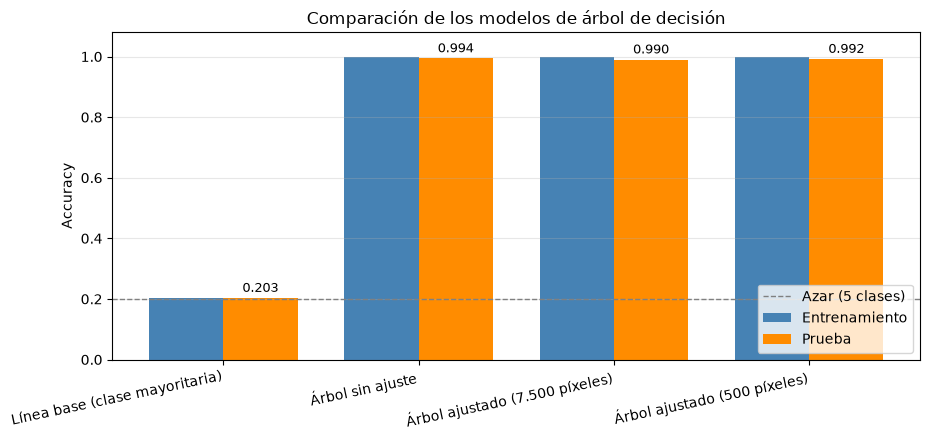

In [20]:
# Comparación visual de accuracy en entrenamiento y prueba
posiciones = np.arange(len(comparacion))
ancho = 0.38

fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.bar(posiciones - ancho / 2, comparacion["Accuracy entrenamiento"],
       width=ancho, label="Entrenamiento", color="steelblue")
ax.bar(posiciones + ancho / 2, comparacion["Accuracy prueba"],
       width=ancho, label="Prueba", color="darkorange")
ax.set_xticks(posiciones)
ax.set_xticklabels(comparacion["Modelo"], rotation=12, ha="right")
ax.set_ylim(0, 1.08)
ax.set_ylabel("Accuracy")
ax.set_title("Comparación de los modelos de árbol de decisión")
ax.axhline(0.2, color="gray", linestyle="--", linewidth=1, label="Azar (5 clases)")
for posicion, valor in zip(posiciones + ancho / 2, comparacion["Accuracy prueba"]):
    ax.text(posicion, valor + 0.02, f"{valor:.3f}", ha="center", fontsize=9)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 13.1 Lectura de la comparación

- La línea base acierta apenas el 20,3 %, equivalente a elegir siempre la clase mayoritaria. El árbol supera ese valor por más de 78 puntos porcentuales, así que el aprendizaje es real y no un efecto del balance de clases.
- El árbol sin ajuste y el árbol ajustado son estadísticamente equivalentes en prueba: 99,41 % frente a 99,01 %. La diferencia corresponde a 4 imágenes de 1.014 y está dentro del error de muestreo. El mejor modelo según validación cruzada (entropía, profundidad 10, `min_samples_leaf=1`, todas las variables) se conserva como modelo final porque la selección se hizo sin mirar el conjunto de prueba.
- La reducción a 500 píxeles mantiene un 99,21 % de accuracy y reduce el tiempo de ajuste de 1,76 s a 0,08 s (aproximadamente 21 veces menos). Para un problema con imágenes de 75x100, la resolución completa no aporta una ventaja práctica.
- El árbol ajustado usa 41 hojas y solo 40 píxeles con importancia mayor que cero. Esa concentración explica su interpretabilidad: las decisiones dependen de una región pequeña de la imagen, no de los 7.500 píxeles.


## 14. Conclusiones, trabajo futuro e implicaciones éticas

### 14.1 Conclusiones

El objetivo propuesto se cumplió: se construyó un flujo completo de clasificación supervisada para las vocales **A, E, I, O, U**, se convirtieron las imágenes a blanco y negro con el método de Otsu y se entrenó un árbol de decisión cuyos hiperparámetros se ajustaron con `GridSearchCV`.

El modelo final obtuvo **99,01 % de accuracy**, **99,01 % de balanced accuracy** y **99,01 % de F1 macro** sobre 1.014 imágenes no vistas. El árbol tiene 9 niveles y 41 hojas, y utiliza solo 40 de los 7.500 píxeles. Los errores se concentran en confusiones entre vocales de forma parecida: **I** con **A**, **U** con **I**, y **U** con **O**. La conversión a blanco y negro fue determinante: eliminó variaciones de iluminación y permitió que reglas simples separaran las clases.

La comparación mostró que el ajuste de hiperparámetros no mejora de forma significativa a un árbol sin ajuste en este conjunto, porque el problema ya es casi separable. La reducción a 500 píxeles conserva el desempeño con un costo computacional mucho menor. La partición agrupada por identificador de aumento evitó que variantes del mismo trazo aparecieran a la vez en entrenamiento y prueba, lo que hace la estimación más honesta.

### 14.2 Limitaciones y trabajo futuro

- El dataset es más sencillo que la escritura real: las imágenes están centradas, tienen un estilo de trazo grueso y un fondo relativamente uniforme. Un accuracy de 99 % no implica el mismo desempeño en fotografías de cuadernos.
- La vocal **O** se aproxima con el dígito **0**. En una aplicación real habría que entrenar con la letra O y distinguirla explícitamente del cero.
- Falta comparar el árbol con los demás métodos de la guía (**regresión multivariada**, **random forest**, **MLP** y **DNN**). Esa comparación permitirá saber si un modelo más complejo justifica su costo.
- Se puede ampliar la experimentación con validación por escritor, aumento de datos controlado, poda por complejidad de costo (`ccp_alpha`), selección de características y calibración de probabilidades.
- La reducción de resolución (20x25) es una línea prometedora para modelos ligeros, pero debe validarse con escritores y estilos no vistos.

### 14.3 Implicaciones éticas

- **Sesgo y representatividad:** el dataset no representa todos los estilos de escritura, edades, culturas ni condiciones motrices. Un modelo entrenado así puede fallar más con escritores atípicos. Cualquier uso real debe evaluarse por subgrupos.
- **Privacidad:** las imágenes de manuscritos pueden contener datos personales. Su recolección, almacenamiento y uso requieren consentimiento y medidas de seguridad.
- **Decisiones automatizadas:** un OCR académico o administrativo no debe usarse como única fuente para calificar, diagnosticar o tomar decisiones legales. Se requiere revisión humana y la posibilidad de corregir.
- **Transparencia:** el árbol es interpretable, pero sus reglas sobre píxeles no explican el contexto de la escritura. La aplicación debe informar sus límites, su tasa de error y el alcance de las clases reconocidas.
- **Uso responsable del dataset:** se debe respetar la licencia de la fuente y no presentar los resultados como un sistema listo para producción.

### 14.4 Referencias

- Kaggle. *Handwriting Letter and Number Dataset*. https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Transactions on Systems, Man, and Cybernetics*, 9(1), 62-66.
- Breiman, L., Friedman, J., Stone, C. J., & Olshen, R. A. (1984). *Classification and Regression Trees*. Wadsworth.
- scikit-learn. *Decision Trees* y *GridSearchCV*. https://scikit-learn.org/stable/modules/tree.html
